# 公開スペクトルによる、未報告の白色矮星の色の探索

> **v0.1の保存版ノートブックです。数値出力は初版のまま保持しています。** v0.2ではMWDD経由SDSSのFν/Fλ混在を修正しました。現在は**適格7,473記録・強外れ308天体キー**であり、以下の旧9,023 / 337は過去の集計です。**WD J1323−0129の独立SDSSによる色の裏付けは撤回しました。** SDSSの単位は未解決、元Gaia XPは取得できておらず、DESI単独装置の色候補として残ります。[現行研究報告](research/README.ja.md)・[English report](research/README.md)・[追加研究ノートブック](research/research_extension.ipynb)を参照してください。発起人・管理者は**Shota Moriwaki**で、ChatGPTの支援を含む未査読研究です。この冒頭表示だけを追加し、元のコードセル・保存出力・他の説明セルは保持しています。現行コードでの再実行は新たな実行であり、元の実行環境の凍結ではありません。

**解析日：2026年10月18日。実行済み研究ノート。**

[English notebook](white_dwarf_colour_research.ipynb) · [日本語レポート](docs/report.ja.md) · [English report](docs/report.en.md) · [再現手順](docs/reproducibility.en.md) · [研究上の位置づけ](docs/research-integrity.md)

公開されたスペクトルを実際に再解析し、Hollands et al. (2026) の236名称の対象一覧にない、黄緑色候補 **WD J0913+4434 / WD J0429−0354**、ピンク色候補 **WD J1329+0033**、異常な黄色の候補 **WD J1323−0129** を抽出した。

新規性の候補は、既知の星について計算した **人間の視覚に対する色度** である。天体そのもの、温度、元素、吸収機構を新発見したという主張ではない。確認した先行研究でこれらの人間視覚色の報告は見つからなかったが、世界的優先権は証明していない。

このノートは保存済み全走査表を集計し、主要候補の色を同梱した元スペクトルから再計算する。全9,902記録の再走査は `download_frozen_spectra.py` と `run_full_screen.py` で再現できる。

**作成主体と位置づけ：** この解析・コード・文章は、ユーザーの研究依頼に応じてChatGPTが生成した、AIによる未査読の研究成果物である。査読論文や専門研究者による独立した発見の確認ではない。元観測・分類・モデルの功績は引用した観測チームと著者に帰属する。候補という位置づけと不確かさを、再利用時にも保持する。

英語版と日本語版は同じ9個のコードセルを共有する。表・図・実行メッセージは両版とも英語である。大きなメタデータは `project_io` を通じて `.json.gz`・`.csv.gz` を読み込む。

In [1]:
from pathlib import Path
import hashlib, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image
from project_io import read_dataframe, load_json
ROOT=Path.cwd().resolve()
if not (ROOT/'colour_pipeline.py').exists():
    raise RuntimeError('Open this notebook with the research repository root as its working directory.')
import colour_pipeline as c
from validate_candidates import anchors, get_arrays
assert Path(c.__file__).resolve().parent==ROOT.resolve(), 'Imported a different project copy.'
pd.set_option('display.max_columns',16)
summary=load_json(ROOT/'results/screen_summary.json')
display(pd.Series(summary).to_frame('value'))
print('Python:',sys.version.split()[0])
print('numpy:',np.__version__)


,value
input_mwdd_spectra,8505
input_mwdd_identifiers,5548
input_sdss_spectra,1397
input_sdss_identifiers,1383
combined_spectrum_records,9902
combined_identifiers_after_5arcsec_match,6004
screen_eligible_records,9023
known_hollands_matched_records,346
calibrated_records,4218
screen_definition,SDSS/DESI/GaiaXP F_lambda source convention; C...


Python: 3.12.14
numpy: 2.5.4


## 1. 探索範囲と選別

MWDDの163,279行のカタログからDQ/DZを含む分類を中心に選び、既知の色の検証用対象を加えた5,548天体について8,505スペクトルを取得した。別経路でSDSSのQ/Z型1,343観測とDA/DC/DB対照各18観測、合計1,397本を取得した。**合計9,902はデータ記録数で、独立した天体数ではない。** 座標5秒角の暫定照合後は6,004名称単位となるが、高固有運動の重複を完全に排除した人口統計値としては扱わない。

SDSS・DESI・Gaia XPのFλ形式、CIE感度曲線の99.5%以上の波長被覆、150 Å未満の最大空白を要求する。校正可能な場合はgriへの一次の等級傾斜を使い、測光誤差0.10等以上、最大残差0.15等以上、傾斜の絶対値0.25等/1,000 Å以上を採用しない。校正できないスペクトルも探索用としてラベルを残すが、その色だけで有力候補にしない。

旧観測やSPYの連続光正規化済みデータは、Fλの形が保証できないため候補判定から外した。全ての外れ値を新発見と呼ぶことはしない。

以下の対照表は**保存済みの走査結果**である。同梱された54本のSDSS元FITSを検証し色を再計算する場合は、`python scripts/verify_reproduction.py --with-controls` を実行する。

In [2]:
all_spectra=read_dataframe(ROOT/'results/all_spectra_screen.csv',dtype={'source_id':'string'},low_memory=False)
display(pd.crosstab(all_spectra.archive_origin,all_spectra.kind))
controls=all_spectra[all_spectra.selection_group.fillna('').str.startswith('control_')]
control_summary=controls.groupby('selection_group').agg(spectra=('wdid','size'),maximum_Duv_distance=('distance_planck_uv','max'))
display(control_summary)
assert len(controls)==54
assert (controls.distance_planck_uv<0.01).all()
print('Archived control result: all 54 observations lie below the distance > 0.01 outlier threshold. Raw controls are not rerun in this notebook.')


kind,DESI,Gaia_XP,SDSS,SPY,other_ground_or_archive
archive_origin,,,,,
MWDD,1967,3499,2232,117,690
SDSS_DR17_direct,0,0,1397,0,0


,spectra,maximum_Duv_distance
selection_group,,
control_DA,18,0.006706
control_DB,18,0.004092
control_DC,18,0.001981


Archived control result: all 54 observations lie below the distance > 0.01 outlier threshold. Raw controls are not rerun in this notebook.


## 2. 色の定義と実装

明所視のCIE 1931・2度標準観測者を用い、波長ごとのエネルギー流束を積分する。

$$ (X,Y,Z)=\int_{360\,{\rm nm}}^{830\,{\rm nm}}F_\lambda(\lambda)(\bar x,\bar y,\bar z)\,d\lambda. $$

$$x=X/(X+Y+Z),\quad y=Y/(X+Y+Z),\quad u=4x/(3-2x+12y),\quad v=6y/(3-2x+12y).$$

符号付きDuvはCIE 1960の黒体軌跡までの最短距離に上下の符号を付けた指標である。**正のDuvだけで緑色とは判定しない。** 緑寄りの目安として線形sRGBでGがR・Bを上回るかも保存する。黒体軌跡は1,000 Kから10⁸ KとRayleigh–Jeans極限を含む。表示色はD65白色点のsRGBに変換し、最大チャンネルを1に揃えてから正しい伝達関数を適用する。

地球から見た写真の色ではなく、受信スペクトルから推定した色度である。星表面の実際の輝度、個人差、暗所視、色順応を再現してはいない。負のノイズ画素をゼロに切り上げる処理はしない。

Verified the official CIE MD5 and the colour-matching functions used by the integration.


,candidate,wdid,kind,published_hex,computed_hex,computed_duv,calibration,qualification
0,J0851+1543,WD 0848+159,Gaia_XP,#F1FFF8,#F1FFF7,0.009002,sdss,Observed spectrum closely reproduced
1,J1011+2845,LP 315-42,SDSS,#FF8775,#FF8775,-0.024246,panstarrs,Observed spectrum closely reproduced
2,J1351+2645,SDSS J135123.86+264546.5,SDSS,#F3FFD2,#F9FFCA,0.016288,panstarrs,Model versus observed spectrum
3,J1330+6435,WD 1328+648,SDSS,#DDFFB8,#EDFFA0,0.029051,sdss,Low-S/N observation versus model


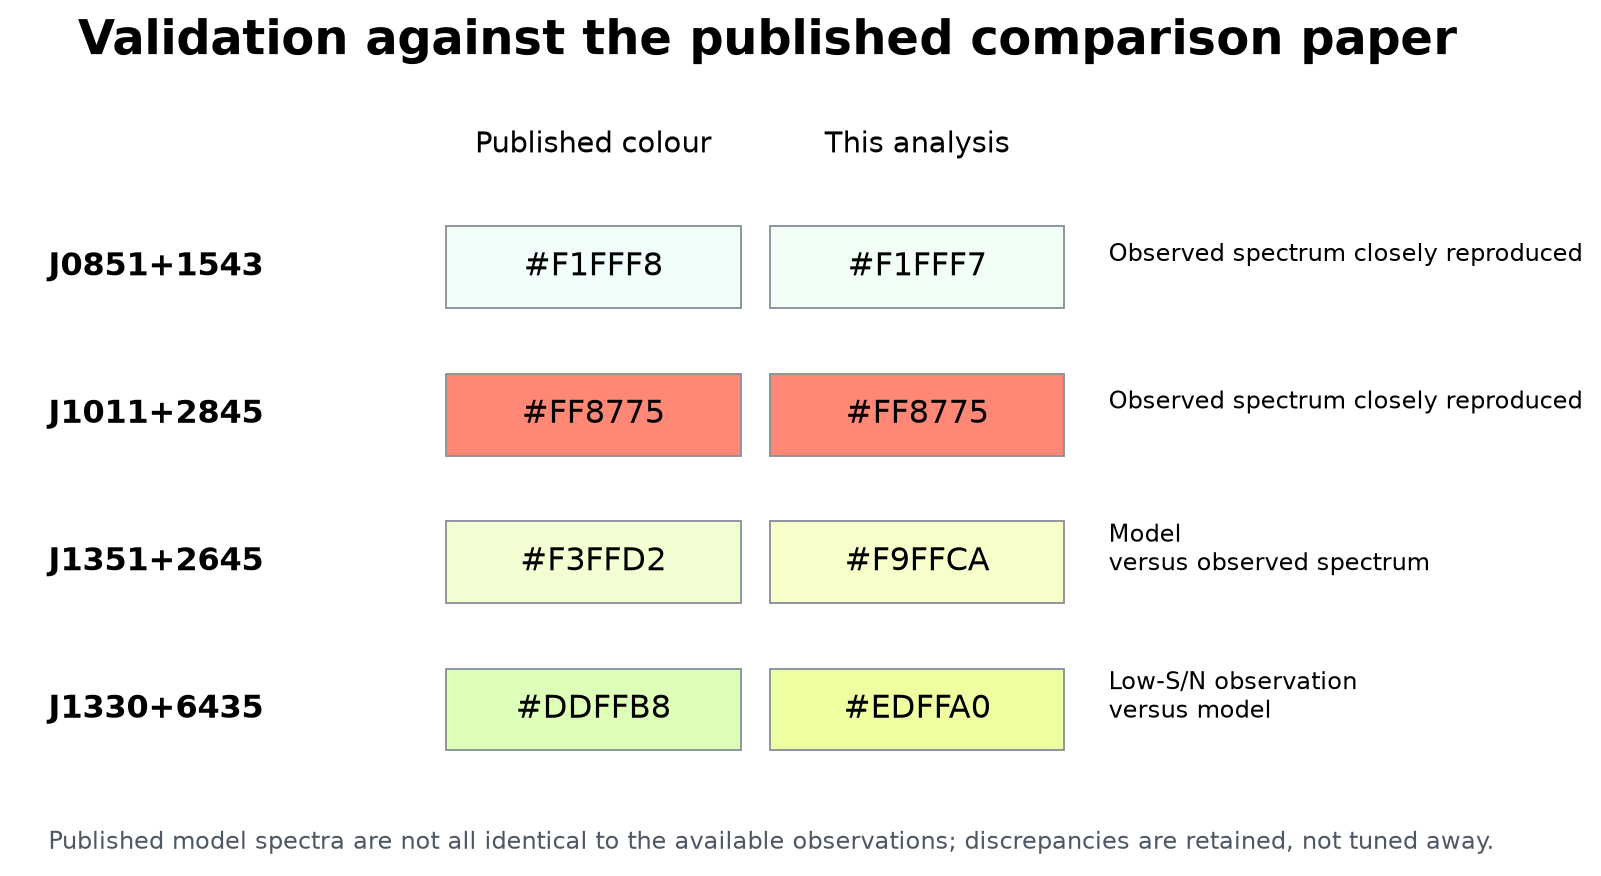

In [3]:
cie_path=ROOT/'reference/CIE_xyz_1931_2deg.csv'
assert hashlib.md5(cie_path.read_bytes()).hexdigest()=='17cca777db64b17170f06f67ce9d3ab7'
official=np.loadtxt(cie_path,delimiter=',')
assert np.max(np.abs(official[:,1:]-c.CMF_V))<1e-12
print('Verified the official CIE MD5 and the colour-matching functions used by the integration.')
display(read_dataframe(ROOT/'results/baseline_reproduction.csv'))
display(Image(filename=str(ROOT/'figures/baseline_reproduction.png')))


緑色の既知例J0851+1543は公表色 `#F1FFF8` に対し `#F1FFF7`、ピンク色J1011+2845は今回のPS1校正で `#FF8775` と一致した。一方、元論文のモデルと観測スペクトルが違う場合の差も残した。特にJ1330+6435は低い信号対雑音比の観測からの再現であり、モデルの正確な色と一致したとは主張しない。

## 3. 主要候補の実測結果

以下の代表値は全て **DESIスペクトルをPan-STARRS griで補正**した同一条件である。各天体の分類・温度は既存カタログ由来で、今回新たに大気モデルをフィットした結果ではない。

,candidate,source_id,hex,x,y,duv,duv_mc_p025,duv_mc_p975
0,J0913+4434,818833831355548928,#F1FFC9,0.335479,0.383550,0.019010,0.016952,0.021124
1,J0429-0354,3204436719718449280,#F8FFDC,0.328446,0.363530,0.012809,0.011973,0.013651
2,J1329+0033,3711047662972690688,#FFC1CF,0.352451,0.315210,-0.022652,-0.024811,-0.020482
3,J1323-0129,3638333660492606976,#FFE86A,0.408297,0.450138,0.023482,0.020943,0.025965


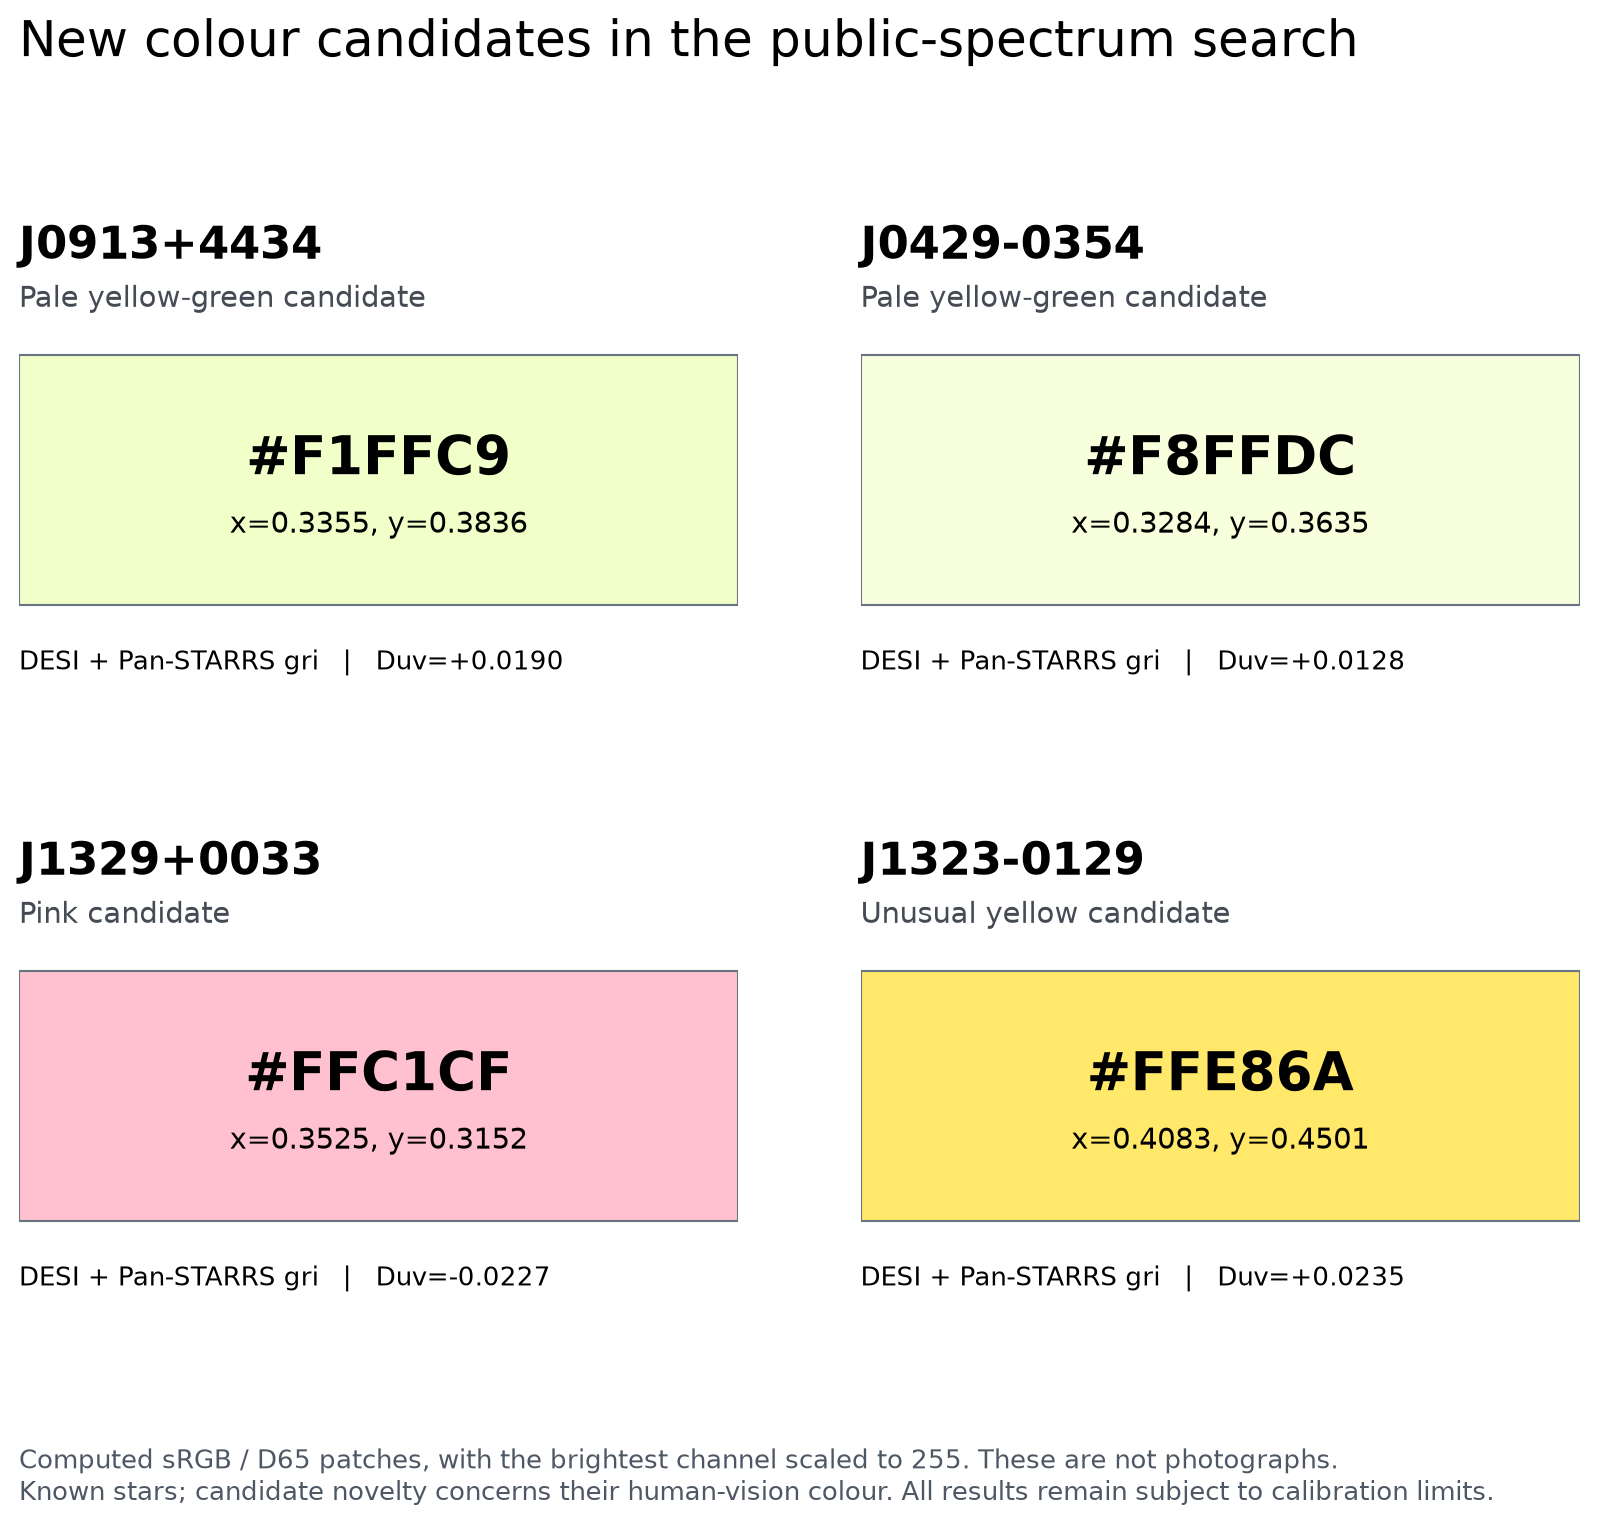

In [4]:
headline=read_dataframe(ROOT/'results/headline_candidates.csv',dtype={'source_id':'string'})
display(headline[['candidate','source_id','hex','x','y','duv','duv_mc_p025','duv_mc_p975']])
display(Image(filename=str(ROOT/'figures/candidate_colours.png')))


### 元スペクトルからの再計算

同梱した公開CSVのSHA256を確認し、同じ校正・CIE積分を再実行する。Gaiaの巨大な数値IDは文字列として保持する。

In [5]:
manifest=load_json(ROOT/'mwdd/manifest_enriched.json')
recomputed=[]
for _,expected in headline.iterrows():
    rec=next(r for r in manifest if r.get('source_id')==expected.source_id and r.get('kind')=='DESI' and r.get('parsed_path'))
    rawpath=c.data_path(rec['raw_path'])
    assert hashlib.sha256(rawpath.read_bytes()).hexdigest()==rec['sha256']
    w,f,iv=get_arrays(rec)
    raw_matrix=np.loadtxt(rawpath,delimiter=',',skiprows=2,ndmin=2)
    raw_columns=rawpath.read_text().splitlines()[1].split(',')
    assert np.array_equal(w,raw_matrix[:,raw_columns.index('wavelength')],equal_nan=True)
    assert np.array_equal(f,raw_matrix[:,raw_columns.index('flux')],equal_nan=True)
    system,obs,errors,origin=next(a for a in anchors(rec) if a[0]=='panstarrs')
    fc,cal=c.recalibrate_gri(w,f,obs,errors,system)
    correction=10**(-.4*(cal['cal_offset_mag']+cal['cal_tilt_mag_per_1000A']*(w-6200)/1000))
    value=c.integrate_colour(w,fc,None if iv is None else iv/correction**2,mask_sky=True)
    assert abs(value['x']-expected.x)<1e-10
    assert abs(value['duv']-expected.duv)<1e-10
    assert value['hex']==expected.hex
    recomputed.append({'candidate':expected.candidate,'sha256_verified':True,'x':value['x'],'y':value['y'],'Duv':value['duv'],'sRGB':value['hex']})
display(pd.DataFrame(recomputed))


,candidate,sha256_verified,x,y,Duv,sRGB
0,J0913+4434,True,0.335479,0.383550,0.019010,#F1FFC9
1,J0429-0354,True,0.328446,0.363530,0.012809,#F8FFDC
2,J1329+0033,True,0.352451,0.315210,-0.022652,#FFC1CF
3,J1323-0129,True,0.408297,0.450138,0.023482,#FFE86A


## 4. 誤差と系統誤差を区別する

DESIは公開画素誤差と測光誤差（最低0.02等）から6,000回の乱数試行を行い、測光への再校正を一次のヤコビアンで追随させ、その後の色積分は非線形に計算した。表示される95%区間は、この条件下の測定誤差区間であり、未知の校正誤差や全探索の誤検出率を含むものではない。DESIの再サンプリング画素間相関は提供されていないため独立画素近似である。

J0913についてはSDSSの元PSF流束も別に取得した。SDSS校正では `#F7FFC6`, Duv≈0.0179、PS1校正では `#F1FFC9`, Duv≈0.0190となり、ともに淡い黄緑領域にある。補正前も同じ傾向である。ただし、さらに−0.10等/1,000 Åという大きい傾斜を加えると、SDSS校正の場合はRがGを上回り得る。色名の境界は校正から完全に独立ではない。

このノートでは保存済みの誤差区間を読み込む。6,000回の乱数試行そのものは再実行しない。

,candidate,cal_system,hex,duv,duv_mc_p025,duv_mc_p975,green_channel_margin
9,J0913+4434,none,#F5FFC7,0.018345,NaN,NaN,0.090032
10,J0913+4434,sdss,#F7FFC6,0.017886,0.015759,0.020092,0.069286
11,J0913+4434,panstarrs,#F1FFC9,0.019010,0.016952,0.021124,0.119571
14,J0429-0354,none,#F5FFDE,0.013183,NaN,NaN,0.088575
15,J0429-0354,panstarrs,#F8FFDC,0.012809,0.011973,0.013651,0.064939


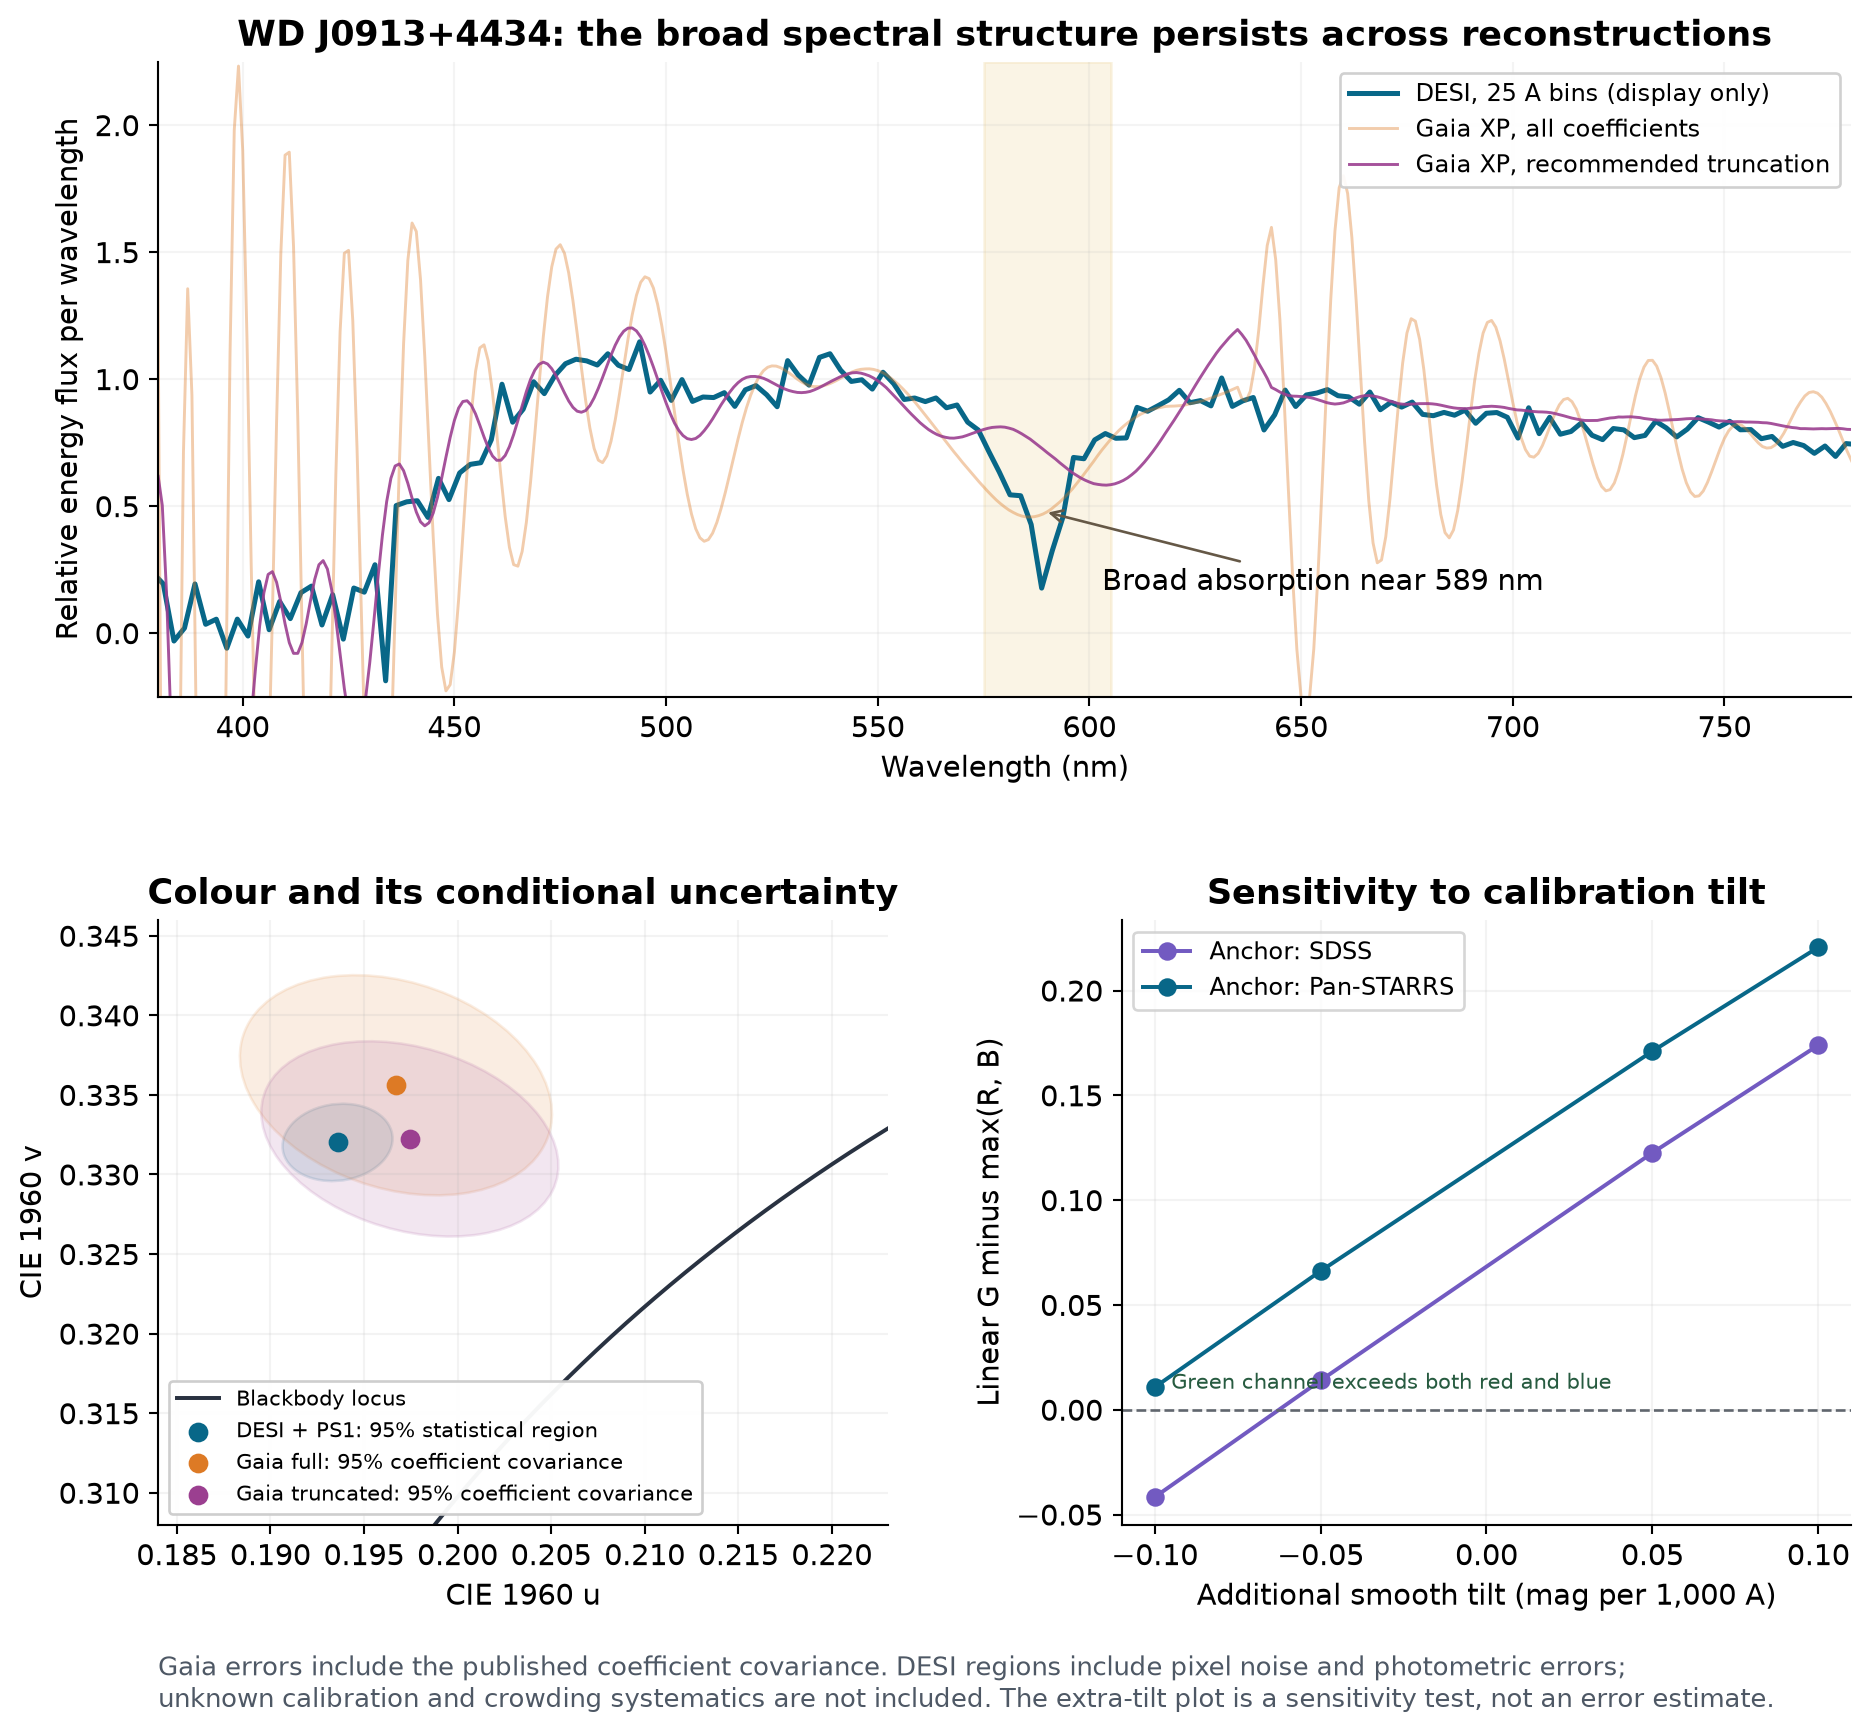

In [6]:
validation=read_dataframe(ROOT/'results/candidates/validated_colours.csv',dtype={'source_id':'string'})
display(validation[(validation.candidate.isin(['J0913+4434','J0429-0354'])) & (validation.kind=='DESI')][['candidate','cal_system','hex','duv','duv_mc_p025','duv_mc_p975','green_channel_margin']])
display(Image(filename=str(ROOT/'figures/j0913_validation.png')))


### Gaiaの元係数・全相関で確認した限界

MWDDのGaia XPファイルには誤差がないため、それを誤差ゼロとして扱うことはできない。ESAのXP_CONTINUOUS元係数と相関を取得し、GaiaXPy 2.1.5でスペクトルを再構成した。全55基底と、カタログが推奨する基底数への切り詰めの両方を確認し、係数共分散を積分後のXYZまで伝播して各200,000回の乱数試行を行った。

**平均の黄緑色は両方の再構成で残るが、Gaia単独で緑色を高い有意度で確定したとは言えない。** 主要な根拠はDESIと独立測光との整合であり、Gaiaは不確かさを伴う追認である。同じ測光を使った校正同士は独立した観測証拠として二重に数えない。

次のセルは同梱された4つの1 nm再構成データから平均色を再計算し、保存済みの共分散による区間を表示する。GaiaXPyによる再構成や乱数試行をこのノート内では再実行しない。全共分散の投影は独立したオフライン検証で確認でき、元係数からの再現手順と限界は[Gaia監査](mwdd/gaia_validation/README.md)に記載した。

In [7]:
gaia_rows=[]
for short in ['j0913','j0429']:
    audit=load_json(ROOT/f'mwdd/gaia_validation/{short}_colour_covariance_audit.json')
    for row in audit['results']:
        if '_1nm.npz' not in row['spectrum']:continue
        spectrum=np.load(ROOT/'mwdd/gaia_validation'/row['spectrum'])
        measured=c.integrate_colour(spectrum['wavelength_nm']*10,spectrum['flux_w_m2_nm'],mask_sky=False)
        assert abs(measured['duv']-row['duv'])<1e-9
        lo,_,_,_,hi=row['duv_percentiles_2_5_16_50_84_97_5']
        gaia_rows.append({'source':short,'spectrum':row['spectrum'],'sRGB':row['hex'],'Duv':row['duv'],'Duv_formal_sigma':row['duv_stat_error'],'95%_low':lo,'95%_high':hi,'formal_fraction_G_largest':row['probability_linear_green_largest_formal_only']})
display(pd.DataFrame(gaia_rows))


,source,spectrum,sRGB,Duv,Duv_formal_sigma,95%_low,95%_high,formal_fraction_G_largest
0,j0913,j0913_full_1nm.npz,#F7FFBF,0.019235,0.003515,0.012362,0.026122,0.850425
1,j0913,j0913_truncated_1nm.npz,#F9FFC9,0.016351,0.003267,0.009945,0.022738,0.777895
2,j0429,j0429_full_1nm.npz,#FAFFD7,0.012993,0.002204,0.008671,0.017303,0.823040
3,j0429,j0429_truncated_1nm.npz,#F7FFD3,0.014928,0.001801,0.011410,0.018464,0.964910


## 5. 近傍天体と、格下げした候補

J0913には約5.342秒角離れた赤い背景天体がある。SDSSは両者を分離しており対象のCLEAN=1だが、rバンドに補間・宇宙線などのフラグがあり、Gaia BP/RPでも各48回中4回が混合フラグを持つ。混入ゼロとは主張しない。

J0429、J1329、J1323のGaia検索では10秒角以内に他の掲載天体がなかった。これはカタログの検出限界以下の混入まで排除するものではない。J0429のPS1にも同程度に明るい近接天体は見つからず、元の測光値はMWDDと一致した。

高い信号対雑音比で黄緑色に見える **LP 616−53 / J1258+0106** も見つかった。しかし、約2.30秒角の明るい伴星と約1.29秒角の別ソースがあり、Gaiaの混合フラグも多い。そのため主要な新候補から格下げした。極端に青く見えたJ1552+2023は、測光値の大きな誤りと不合理な傾斜補正による偽候補として除いた。

J1323−0129は黄色であり、Duvが正だからといって緑色に数えない。既存論文間で推定温度・重力が大きく変化しているため、今回の色の計算から新しい物理パラメータや組成の発見には進まない。

### 独立したDESIカタログの混入推定

[Swan et al. 2026](https://arxiv.org/html/2609.04314v1) の公式表を追加取得した。主要4候補のDESI混入比は、Gaia近傍天体・固有運動・シーイングを使ったガウスPSFモデルではごく小さい。一方、LP 616−53はWD+MS分類で、DESIの近傍光／対象光比は約0.0307、SDSSで約0.706、PS1で約0.765だった。後者を単独星の色の主張から外す判断が裏付けられた。

この指標はPSFの翼やスペクトルのクロストークを扱っていないので、混入の厳密な上限ではない。また同論文には、別天体のNa様吸収が再観測では確認されなかった例もある。今回の平均色の測定と、吸収元素・物理機構の確定は分ける。

In [8]:
contamination=read_dataframe(ROOT/'novelty/swan2026_candidate_contamination.csv',dtype=str)
display(contamination)


,label,gaia_source_id,WDJname,swan_specType,swan_specType_confidence,nExposures,nNeighbours_DESI,neighbour_to_target_flux_DESI,neighbour_to_target_flux_PanSTARRS,neighbour_to_target_flux_SDSS,neighbour_to_target_flux_Gaia_G,neighbour_to_target_flux_Gaia_BPRP,exposure_seeing_arcsec,exposure_MJD,exposure_ids,catalogue_fractionMasked_Z
0,J0429-0354,3204436719718449280,WDJ042944.71-035422.00,DZ,0.85,1,5,0.0,1.006227530083581e-27,6.993563195695968e-26,0.0,3.079972496130789e-29,1.1572496861048602,59629.10387012,122747,0.005206525511975
1,J0913+4434,818833831355548928,WDJ091336.37+443405.41,DZ,0.9090909090909092,1,6,3.1249436026955074e-14,1.0522015426392375e-05,5.346537044726651e-06,0.0,3.035589287944712e-05,0.8095058990275189,59519.52952731,106892,0.001041305102395
2,J1258+0106 / LP616-53,3690311908759604608,WDJ125858.25+010632.45,WD+MS,0.6113736519739955,1,9,0.0307208415454045,0.7652780342274895,0.7063885771493613,0.0,0.8599886082217859,1.5454575735315532,59652.35823236,126067,0.0055536272127733
3,J1323-0129,3638333660492606976,WDJ132312.76-012923.67,DZ,0.7657531818827245,1,5,0.0,2.470821562768092e-30,2.1492752558737458e-29,0.0,2.105267363811396e-31,1.1583782464059724,59370.15122237,91167,0.0048594238111766
4,J1329+0033,3711047662972690688,WDJ132942.69+003336.60,DQ,1.0,2,2,8.292924416506698e-37,3.658319020621624e-24,2.517196926955602e-22,0.0,1.6342086498484415e-25,1.8912097789554336;0.9576157365698404,59607.5103631;59650.41160872,120460;125840,0.503123915307185
5,J1401+3903,1496016553207149952,WDJ140155.42+390326.47,DQ,1.0,1,2,0.0,0.0,0.0,0.0,0.0,1.0302681133179736,59386.15304133,95393,0.003123915307185


## 6. どこまでが新しい研究結果か

既知名・別名・Gaia ID・位置を照合し、Hollands2026の全236名称とHollands2017の231個のDZ親カタログから除外した。候補の過去の分類や大気モデル、SIMBAD文献、Kilic・Vincent等の論文本文と図を確認した。既存のモデルフィットは、J0913の幅広い金属吸収やJ1329の炭素分子の吸収と整合している。これらの機構自体は既知である。

今回の新しい測定は、対象外の既知星について、公開Fλスペクトルから標準化した人間視覚色を求め、校正・誤差・原論文との重複を検査したことにある。先行研究に報告が見当たらなかった範囲を明示する。未索引の研究、公開されていない計算、全ての補足資料まで不存在を証明したわけではない。

この探索はDQ/DZを意図的に多く含むため、緑色白色矮星の宇宙全体での割合は算出しない。54対照が正常でも、何千件もの探索後の世界初の発見有意度を保証するものではない。

Prior-literature and source-identity evidence records: 49


,candidate,gaia_source_id,source,url,check,establishes,limitation
0,J0913+4434,818833831355548928,SIMBAD object record,https://simbad.cds.unistra.fr/simbad/sim-id?Id...,"Read Gaia-ID-resolved identity, epoch-labelled...",The astronomical object is already catalogued;...,SIMBAD bibliography is not complete or instant...
1,J0913+4434,818833831355548928,Hollands2026 Tables3-6,https://arxiv.org/html/2610.18966v1,Compared SIMBAD J2000 coordinates against all2...,This object is absent from the named object ta...,The encoded coordinates of the comparison tabl...
2,J0913+4434,818833831355548928,Hollands2017 full231 DZ parent catalogue,https://cdsarc.cds.unistra.fr/ftp/J/MNRAS/467/...,Compared against every fixed-width designation...,No hidden match to the larger2017 DZ parent ca...,"This is an identity exclusion, not proof that ..."
3,J0913+4434,818833831355548928,Kilic2026 source table1,https://arxiv.org/abs/2606.25377,Exact GaiaID match in the authors machine-read...,The spectrum classification and atmospheric pa...,These physical measurements are not new result...
4,J0913+4434,818833831355548928,Kilic2026 public model-fit figures,https://doi.org/10.5281/zenodo.20775938,"kilic2026_allfitsDZ.pdf page321 (one-based), r...",A previously computed stellar-atmosphere model...,The plotted spectra are F_nu. Visual agreement...
5,J0913+4434,818833831355548928,Relevant survey full texts,https://arxiv.org/abs/2606.25377 ; https://arx...,Read classification/parameterisation methods a...,The inspected surveys are prior physical/spect...,This conclusion is bounded to the retrieved te...
6,J0913+4434,818833831355548928,Swan2026 DESI DR1 white dwarf catalogue,https://arxiv.org/html/2609.04314v1,Exact Gaia-ID match in the official version1.0...,The object and its spectral class are prior wo...,Flux ratios mean neighbour flux divided by tar...
7,J0913+4434,818833831355548928,Gaia DR3 local field and photometry quality,https://vizier.cds.unistra.fr/viz-bin/asu-tsv?...,Queried10arcsec cone in catalogueI/355/gaiadr3...,Identifies catalogued nearby light sources and...,Only catalogued Gaia DR3 sources in this cone ...


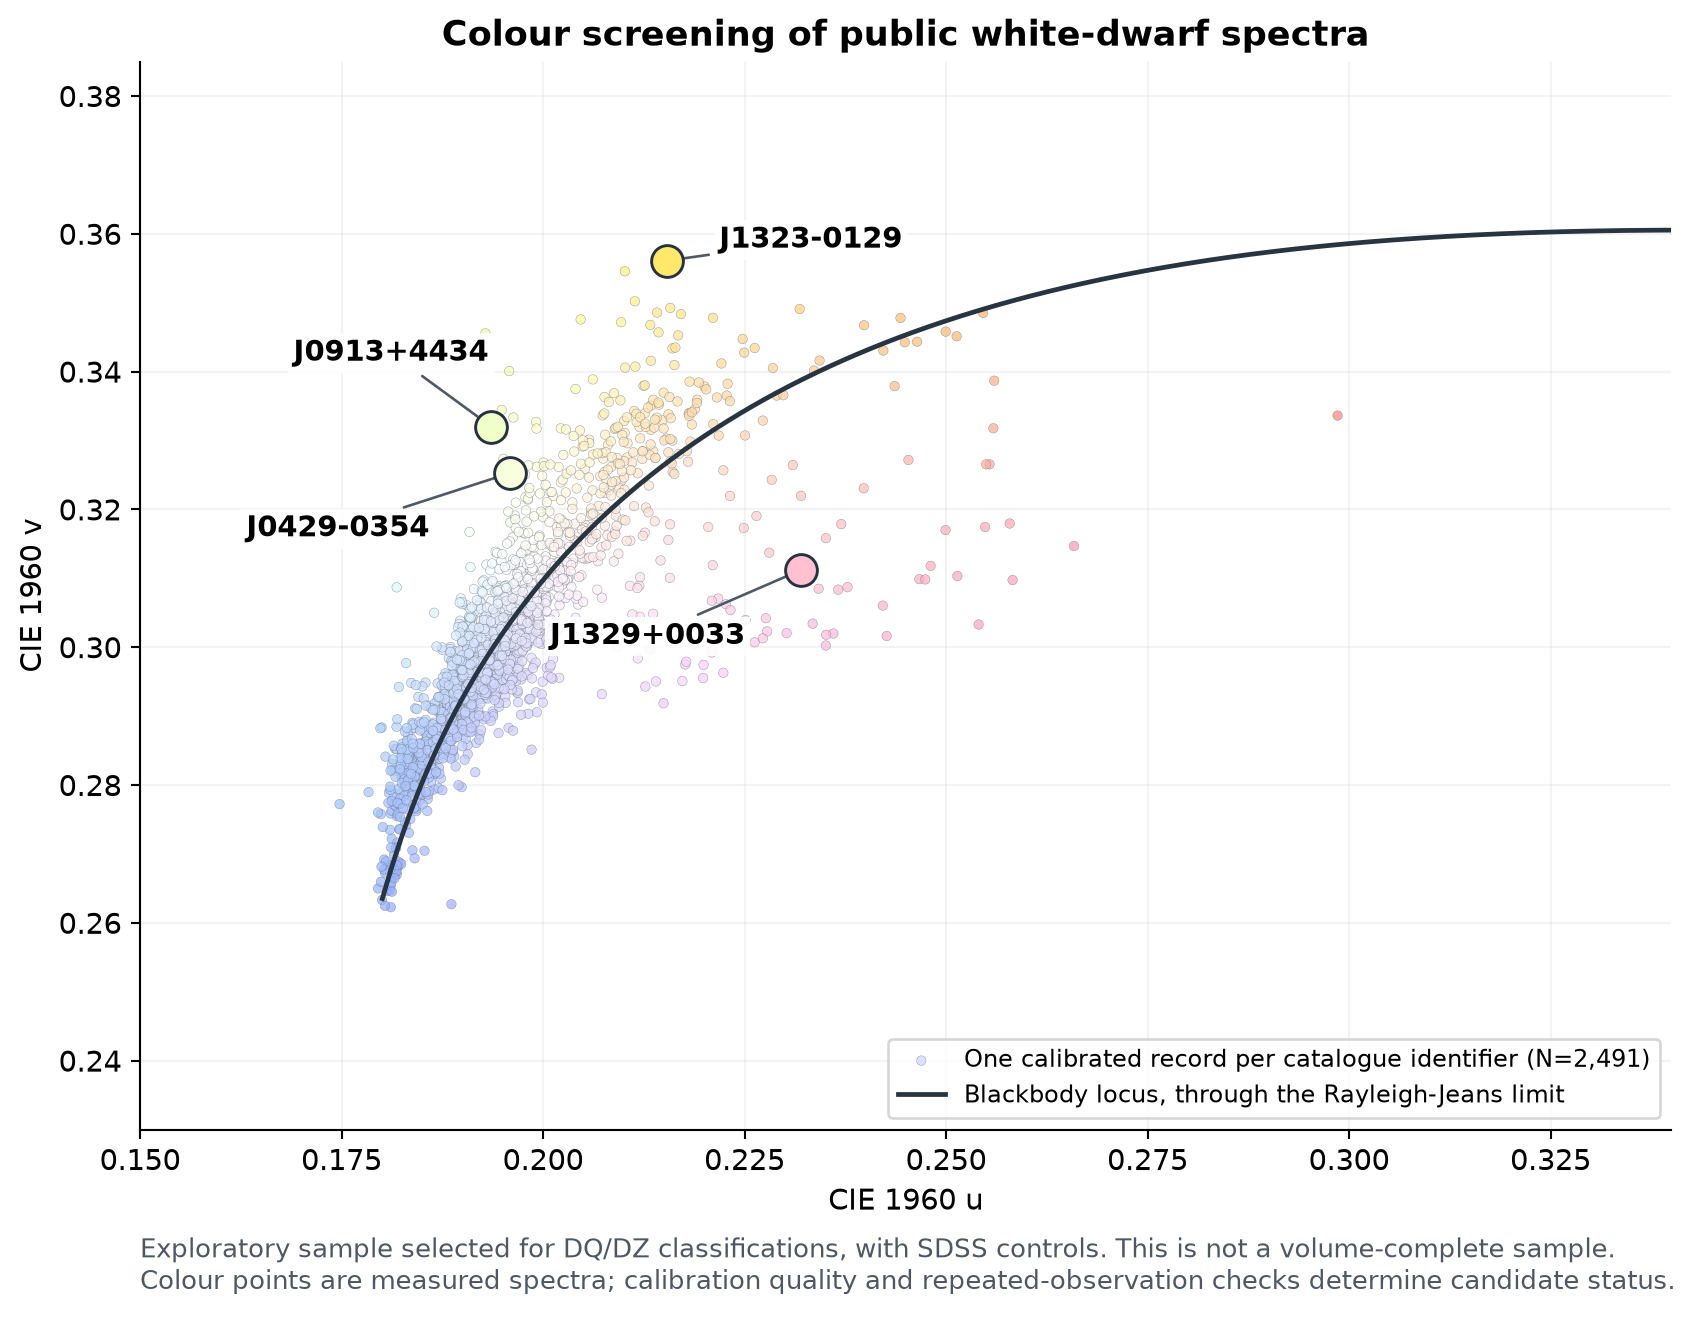

In [9]:
audit=read_dataframe(ROOT/'novelty/novelty_evidence.csv',dtype=str)
print('Prior-literature and source-identity evidence records:',len(audit))
display(audit.head(8))
display(Image(filename=str(ROOT/'figures/survey_colour_plane.png')))


## 7. 追試と次の観測が解決すること

- **今回の再現**：このノートを上から実行する。全走査表と主要候補の元データは同梱されている。
- **両言語版の再生成**：`python make_notebook.py --execute --kernel python3`。別の登録済みカーネルを使う場合は `--kernel` で指定する。科学計算は同じ9セルを共有し、保存時には標準の `python3` カーネル指定に戻す。
- **独立したオフライン検証**：`python scripts/verify_reproduction.py --with-controls`。同梱した元SDSS対照スペクトルとGaia共分散も検証する。
- **全標本の再現**：`python download_frozen_spectra.py` でSHA256を照合しながら元データを取得し、`python run_full_screen.py` を実行する。
- **候補の乱数試行の再現**：`python validate_candidates.py`。Gaiaの元係数からの再構成は別環境で `mwdd/gaia_validation/README.md` に従う。
- **確定度を上げる観測**：候補と近傍星を分離し、可視域全体の相対流束を数%程度で校正する独立の分光観測。これで残る混入・滑らかな校正誤差・再観測の一致を検証できる。
- **論文化時の主張**：標準観測者に対する新しい色度測定と追加候補として提示し、現段階で新天体や世界初を断定しない。大気モデルからの色の予測は追加の物理検証であり、今回実施済みの結果と混同しない。

## 主なデータ・文献

1. [Hollands et al. 2026, Any colour you like](https://arxiv.org/html/2610.18966v1), DOI: 10.1093/rasti/rzag069.
2. [Montreal White Dwarf Database](https://www.montrealwhitedwarfdatabase.org/), Dufour et al. 2017.
3. [Kilic et al. 2026, Cool White Dwarfs in DESI DR1](https://arxiv.org/html/2606.25377v2), DOI: 10.3847/1538-4357/ae825f. [公開モデル図](https://doi.org/10.5281/zenodo.20775938).
4. [Vincent et al. 2024, Gaia XP classification](https://arxiv.org/abs/2308.05572), DOI: 10.1051/0004-6361/202347694.
5. [Kepler et al. 2019 の元カタログ](https://cdsarc.cds.unistra.fr/ftp/J/MNRAS/486/2169/), DOI: 10.1093/mnras/stz960.
6. [CIE 1931公式等色関数](https://cie.co.at/datatable/cie-1931-colour-matching-functions-2-degree-observer), DOI: 10.25039/CIE.DS.xvudnb9b, CC BY-SA 4.0.
7. [Gaia公式データ取得](https://www.cosmos.esa.int/web/gaia-users/archive/programmatic-access)、[GaiaXPy公式ドキュメント](https://gaia-dpci.github.io/GaiaXPy-website/)、[SDSS DR17](https://www.sdss4.org/dr17/spectro/spectro_basics/)、[PS1 API](https://catalogs.mast.stsci.edu/docs/panstarrs.html)。

生スペクトル、元係数、使用した表のURLとSHA256は同梱のマニフェストに記録した。原観測・カタログ・モデルの著者に帰属するデータを利用した再解析であり、査読を受けた論文ではない。